In [2]:
import pandas as pd
df = pd.read_csv("../data/cardio_train.csv", sep=";")
df = df.drop(columns=["id"])

In [3]:
df.shape
df.dtypes
df.describe()
df["cardio"].value_counts(normalize=True)

cardio
0    0.5003
1    0.4997
Name: proportion, dtype: float64

In [4]:
df.describe()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [5]:
clean = df[
    (df["ap_hi"] >= 90) & (df["ap_hi"] <= 200) &
    (df["ap_lo"] >= 60) & (df["ap_lo"] <= 130) &
    (df["height"] >= 120) & (df["height"] <= 220) &
     (df["weight"] >= 30) & (df["weight"] <= 200) &
    (df["ap_lo"] < df["ap_hi"])
].copy()
print(clean.shape[0])

68374


In [6]:
clean["age_years"] = clean["age"] / 365
clean["bmi"] = clean["weight"] / (clean["height"]/ 100)**2
print(clean["bmi"].describe())

count    68374.000000
mean        27.460413
std          5.252019
min         10.726644
25%         23.875115
50%         26.346494
75%         30.119376
max        108.169847
Name: bmi, dtype: float64


In [7]:
clean = clean[(clean["bmi"] >= 15) & (clean["bmi"] <= 60)]
print(clean.shape[0])

68331


In [8]:
from sklearn.model_selection import train_test_split

X = clean.drop(columns=["cardio", "age", "height", "weight"])
y = clean["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.columns)

Index(['gender', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco',
       'active', 'age_years', 'bmi'],
      dtype='str')


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       0.71      0.78      0.74      6903
           1       0.75      0.67      0.71      6764

    accuracy                           0.73     13667
   macro avg       0.73      0.73      0.73     13667
weighted avg       0.73      0.73      0.73     13667

[[5381 1522]
 [2201 4563]]


In [10]:
from sklearn.metrics import roc_auc_score

proba = pipe.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, proba))

ROC-AUC: 0.7921614849104851


In [11]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, max_depth=6, min_samples_split=50)),
])
model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, max_depth=6, min_samples_split=50)
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc")

pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))
proba = pipe.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, proba))


print(scores)
print("среднее:", scores.mean())

              precision    recall  f1-score   support

           0       0.71      0.80      0.75      6903
           1       0.76      0.67      0.71      6764

    accuracy                           0.73     13667
   macro avg       0.74      0.73      0.73     13667
weighted avg       0.74      0.73      0.73     13667

[[5503 1400]
 [2251 4513]]
ROC-AUC: 0.7997374790466834
[0.78953381 0.79940268 0.79927033 0.79961566 0.79643295]
среднее: 0.7968510861244356


In [12]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(verbose=0, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc")
print(scores, scores.mean())

[0.79303915 0.79878433 0.80182661 0.80193073 0.798455  ] 0.7988071616981659


In [13]:
model = CatBoostClassifier(verbose=0, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))
print("ROC-AUC test:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

           0       0.72      0.78      0.75      6903
           1       0.75      0.70      0.72      6764

    accuracy                           0.74     13667
   macro avg       0.74      0.74      0.74     13667
weighted avg       0.74      0.74      0.74     13667

[[5357 1546]
 [2039 4725]]
ROC-AUC test: 0.8008661011209398


In [14]:
threshold = 0.35
pred_new = (proba >= threshold).astype(int)

print(confusion_matrix(y_test, pred_new))
print(classification_report(y_test, pred_new))

[[3996 2907]
 [1125 5639]]
              precision    recall  f1-score   support

           0       0.78      0.58      0.66      6903
           1       0.66      0.83      0.74      6764

    accuracy                           0.70     13667
   macro avg       0.72      0.71      0.70     13667
weighted avg       0.72      0.70      0.70     13667



In [15]:
import numpy as np

pred_035 = (proba >= 0.35).astype(int)

fn_mask = (y_test.values == 1) & (pred_035 == 0)   # болен, но сказали «здоров» — пропущенные
tp_mask = (y_test.values == 1) & (pred_035 == 1)   # болен и поймали

fn = X_test[fn_mask]   # портрет пропущенных
tp = X_test[tp_mask]   # портрет пойманных

print("Пропущенные (FN):")
print(fn.describe())
print(fn["ap_hi"], fn["ap_lo"] , fn["age_years"], fn["cholesterol"], fn["bmi"])
print(tp["ap_hi"],tp["ap_lo"] , tp["age_years"], tp["cholesterol"], tp["bmi"])
print("\nПойманные (TP):")
print(tp.describe())

Пропущенные (FN):
            gender        ap_hi        ap_lo  cholesterol         gluc  \
count  1125.000000  1125.000000  1125.000000   1125.00000  1125.000000   
mean      1.350222   116.343111    77.048000      1.09600     1.100444   
std       0.477252     7.049366     6.393071      0.31231     0.381570   
min       1.000000    90.000000    60.000000      1.00000     1.000000   
25%       1.000000   110.000000    70.000000      1.00000     1.000000   
50%       1.000000   120.000000    80.000000      1.00000     1.000000   
75%       2.000000   120.000000    80.000000      1.00000     1.000000   
max       2.000000   166.000000   106.000000      3.00000     3.000000   

             smoke         alco       active    age_years          bmi  
count  1125.000000  1125.000000  1125.000000  1125.000000  1125.000000  
mean      0.090667     0.060444     0.851556    50.584743    26.000224  
std       0.287262     0.238414     0.355698     5.331393     4.364317  
min       0.000000     

In [16]:
import pandas as pd
compare = pd.DataFrame({
    "FN_пропущенные": fn.mean(),
    "TP_пойманные": tp.mean(),
})
print(compare)

             FN_пропущенные  TP_пойманные
gender             1.350222      1.352545
ap_hi            116.343111    137.730626
ap_lo             77.048000     86.339245
cholesterol        1.096000      1.600106
gluc               1.100444      1.306792
smoke              0.090667      0.086008
alco               0.060444      0.055861
active             0.851556      0.774251
age_years         50.584743     55.855929
bmi               26.000224     29.111015


/Users/uluana_roshina/Python/ml_middle_journey/cardiovascular-kaggle/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


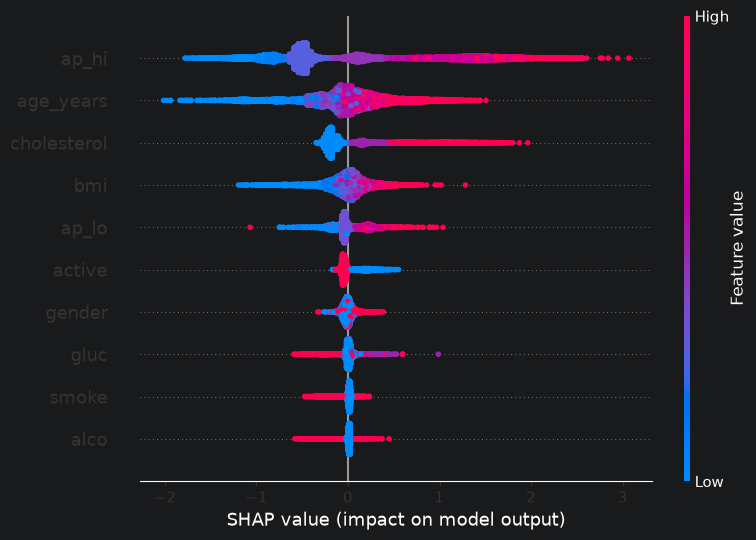

In [20]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

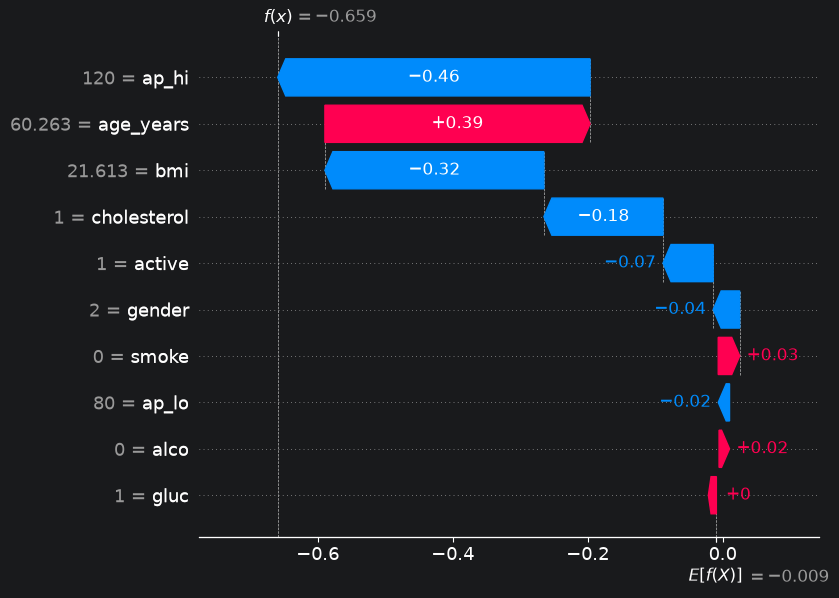

In [21]:

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test.iloc[0],
        feature_names=X_test.columns.tolist(),
    )
)

In [24]:
import numpy as np

pred_035 = (proba >= 0.35).astype(int)
fn_mask = (y_test.values == 1) & (pred_035 == 0)

fn_positions = np.where(fn_mask)[0]
i = fn_positions[0]

print("правда:", y_test.iloc[i], "| прогноз:", pred_035[i])   # ждём 1 и 0

правда: 1 | прогноз: 0


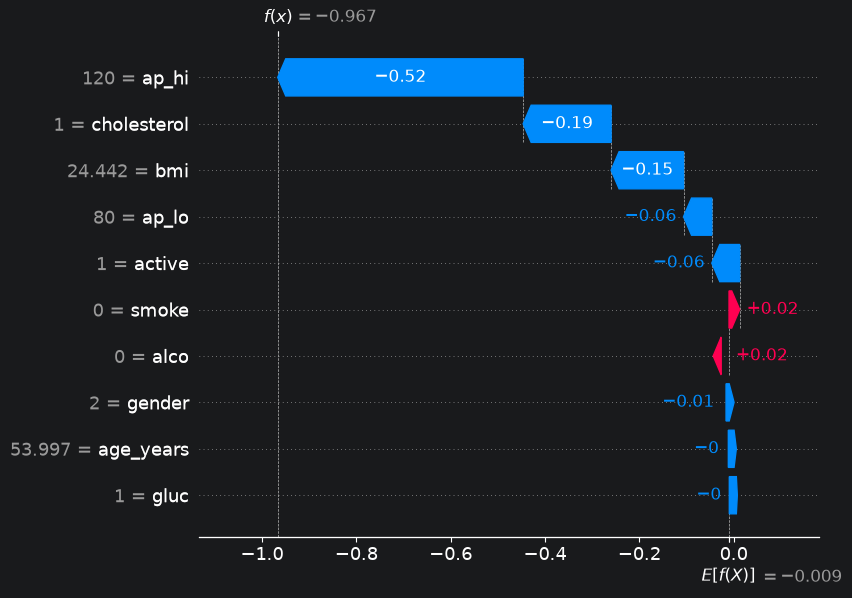

In [25]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[i],
        base_values=explainer.expected_value,
        data=X_test.iloc[i],
        feature_names=X_test.columns.tolist(),
    )
)

In [26]:
import joblib

artifact = {
    "model": model,
    "threshold": 0.35,
    "features": X_train.columns.tolist(),
}
joblib.dump(artifact, "../models/cardio_model.joblib")
print("сохранено")

сохранено


In [17]:
print(clean.shape)

(68331, 14)


In [18]:
df.shape

(70000, 12)

In [19]:
df.dtypes

age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object